# Notebook 01 : théorie et prototype du dilemme répété

**Projet 6, groupe 6.** Ce notebook retrouve les résultats du cours (dilemme à une manche, induction à rebours sur $n$ manches, seuils d'actualisation) puis fait tourner le prototype : tournoi, bruit, réplicateur. Toutes les sorties ci-dessous sont celles de l'exécution du notebook, graine 0 sauf mention contraire. Aucun modèle de langage n'intervient ici.

In [1]:
import sys, random
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from jeux import (T, R, P, S, GAINS, STRATEGIES, STRATEGIES_ETENDUES, est_un_dilemme, match, match_detail,
                  tournoi, replicateur, seuil_rancunier, seuil_tft, ecart_deviation_rancunier, ecart_theorique_rancunier)
np.set_printoptions(precision=3, suppress=True)
print("T, R, P, S =", T, R, P, S, "| dilemme :", est_un_dilemme(), "| 2R =", 2 * R, "> T + S =", T + S)

T, R, P, S = 5 3 1 0 | dilemme : True | 2R = 6 > T + S = 5


## 1. Le dilemme à une manche

Matrices des gains : $A$ pour le joueur 1 (lignes), $B$ pour le joueur 2 (colonnes), indices à partir de 0 avec $0=C$ et $1=D$ (convention commune avec le groupe 1).

In [2]:
A = np.array([[R, S], [T, P]]); B = A.T          # B[i][j] = gain du joueur 2 quand J1 joue i et J2 joue j
def equilibres_purs(A, B):
    return [(i, j) for i in range(A.shape[0]) for j in range(A.shape[1])
            if A[i, j] >= A[:, j].max() and B[i, j] >= B[i, :].max()]
nom = "CD"
print("équilibres de Nash purs :", [(nom[i], nom[j]) for i, j in equilibres_purs(A, B)])
print("D domine strictement C pour J1 :", bool((A[1] > A[0]).all()))
print("(C,C) =", (int(A[0, 0]), int(B[0, 0])), "Pareto-domine (D,D) =", (int(A[1, 1]), int(B[1, 1])))

équilibres de Nash purs : [('D', 'D')]
D domine strictement C pour J1 : True
(C,C) = (3, 3) Pareto-domine (D,D) = (1, 1)


Trahir domine strictement coopérer ($5>3$ et $1>0$), donc $(D,D)$ est l'unique équilibre de Nash alors que $(C,C)$ rapporte plus aux deux joueurs.

## 2. Induction à rebours sur $n$ manches

À la dernière manche, le jeu est un dilemme à une manche. À la manche précédente, le gain de continuation ne dépend pas des actions (on trahira de toute façon à la suivante) : il s'ajoute à toutes les cases et ne change pas les équilibres. On le vérifie par le calcul.

In [3]:
def induction_a_rebours(n):
    chemin, continuation = [], 0.0                    # gain de continuation de chaque joueur, constant
    for restantes in range(1, n + 1):                 # manche numéro n - restantes + 1, en partant de la dernière
        eq = equilibres_purs(A + continuation, B + continuation)
        assert len(eq) == 1, eq
        i, j = eq[0]
        chemin.append((nom[i], nom[j]))
        continuation += A[i, j]
    return chemin[::-1], continuation
for n in (1, 2, 3, 5, 200):
    chemin, total = induction_a_rebours(n)
    print(f"n = {n:3d} : chemin d'équilibre = {set(chemin)} ; gain total par joueur = {total:g} (= n x P = {n * P})")

n =   1 : chemin d'équilibre = {('D', 'D')} ; gain total par joueur = 1 (= n x P = 1)
n =   2 : chemin d'équilibre = {('D', 'D')} ; gain total par joueur = 2 (= n x P = 2)
n =   3 : chemin d'équilibre = {('D', 'D')} ; gain total par joueur = 3 (= n x P = 3)
n =   5 : chemin d'équilibre = {('D', 'D')} ; gain total par joueur = 5 (= n x P = 5)
n = 200 : chemin d'équilibre = {('D', 'D')} ; gain total par joueur = 200 (= n x P = 200)


Le seul équilibre parfait en sous-jeux est « trahir à chaque manche », quel que soit $n$ : c'est le paradoxe du mille-pattes. Sur 200 manches, la théorie prédit $200\times P=200$ points, alors que deux joueurs coopérant obtiendraient $200\times R=600$.

## 3. Horizon indéterminé : seuils d'actualisation

Contre un rancunier, coopérer vaut $R/(1-\delta)$ et trahir dès la première manche vaut $T+\delta P/(1-\delta)$. Le seuil est $(T-R)/(T-P)$.

In [4]:
print("seuil du rancunier  (T-R)/(T-P) =", seuil_rancunier())
print("seuil de TFT, alternance (T-R)/(R-S) =", (T - R) / (R - S), "; seuil retenu pour TFT =", round(seuil_tft(), 4))
for d in (0.4, 0.5, 0.6):
    coop = R / (1 - d); trahir = T + d * P / (1 - d)
    print(f"delta = {d} : coopérer = {coop:.3f}, trahir = {trahir:.3f}, écart (trahir - coopérer) = {trahir - coop:+.3f}")

seuil du rancunier  (T-R)/(T-P) = 0.5
seuil de TFT, alternance (T-R)/(R-S) = 0.6666666666666666 ; seuil retenu pour TFT = 0.6667
delta = 0.4 : coopérer = 5.000, trahir = 5.667, écart (trahir - coopérer) = +0.667
delta = 0.5 : coopérer = 6.000, trahir = 6.000, écart (trahir - coopérer) = +0.000
delta = 0.6 : coopérer = 7.500, trahir = 6.500, écart (trahir - coopérer) = -1.000


Vérification par simulation avec arrêt aléatoire : la partie continue avec la probabilité $\delta$, sa longueur $L$ est géométrique d'espérance $1/(1-\delta)$, et l'écart « trahir moins coopérer » vaut en espérance $T-P+(P-R)/(1-\delta)$, nul exactement en $\delta=1/2$.

In [5]:
print("   delta   simulé (moyenne ± erreur std)    théorique")
for d in (0.4, 0.5, 0.6):
    m, e = ecart_deviation_rancunier(d, parties=60000, seed=5)
    print(f"   {d}    {m:+.3f} ± {e:.3f}                    {ecart_theorique_rancunier(d):+.3f}")

   delta   simulé (moyenne ± erreur std)    théorique
   0.4    +0.655 ± 0.009                    +0.667
   0.5    -0.016 ± 0.012                    +0.000
   0.6    -0.997 ± 0.016                    -1.000


Pour TFT, la déviation qui alterne trahir et coopérer ($T,S,T,S,\dots$) vaut $(T+\delta S)/(1-\delta^2)$ ; on compare à la coopération $R/(1-\delta)$.

In [6]:
for d in (0.6, 2 / 3, 0.7):
    coop = R / (1 - d); alterne = (T + d * S) / (1 - d ** 2); toujours_D = T + d * P / (1 - d)
    print(f"delta = {d:.3f} : coopérer {coop:.3f} | alterner {alterne:.3f} | trahir toujours {toujours_D:.3f}")

delta = 0.600 : coopérer 7.500 | alterner 7.812 | trahir toujours 6.500
delta = 0.667 : coopérer 9.000 | alterner 9.000 | trahir toujours 7.000
delta = 0.700 : coopérer 10.000 | alterner 9.804 | trahir toujours 7.333


## 4. Le tournoi sans bruit (200 manches, auto-jeu compris)

Convention : `M[i][j]` est le score moyen par manche de $i$ contre $j$ ; sur la diagonale, moyenne des deux côtés de l'auto-jeu.

In [7]:
noms, M, classement = tournoi(manches=200, bruit=0.0, seed=0)
print(" " * 11 + "".join(f"{n[:9]:>10}" for n in noms))
for n, ligne in zip(noms, M):
    print(f"{n:>10} " + "".join(f"{v:10.3f}" for v in ligne))
print("\nclassement :", [(n, round(float(v), 3)) for n, v in classement])

            toujours_ toujours_       TFT rancunier    Pavlov aleatoire
toujours_C      3.000     0.000     3.000     3.000     3.000     1.410
toujours_D      5.000     1.000     1.020     1.020     3.000     3.200
       TFT      3.000     0.995     3.000     3.000     3.000     2.280
 rancunier      3.000     0.995     3.000     3.000     3.000     3.165
    Pavlov      3.000     0.500     3.000     3.000     3.000     2.335
 aleatoire      4.060     0.450     2.280     0.515     2.160     2.310

classement : [('rancunier', 2.693), ('TFT', 2.546), ('Pavlov', 2.473), ('toujours_D', 2.373), ('toujours_C', 2.235), ('aleatoire', 1.963)]


Lecture : TFT, le rancunier et Pavlov se coopèrent entre eux (3 par manche) ; toujours trahir exploite toujours coopérer (5 contre 0) mais n'obtient que 1 contre un rancunier ou TFT après la première manche. La ligne « aleatoire » dépend de la graine.

## 5. Effet du bruit

Classements en score moyen par manche, 20 répétitions par paire, graine 0.

In [8]:
resultats = {}
for eps in (0.0, 0.01, 0.05):
    _, Me, cl = tournoi(manches=200, bruit=eps, seed=0, repetitions=20)
    resultats[eps] = (Me, cl)
    print(f"epsilon = {eps}: " + " > ".join(f"{n} {v:.3f}" for n, v in cl))

epsilon = 0.0: rancunier 2.663 > TFT 2.541 > Pavlov 2.466 > toujours_D 2.340 > toujours_C 2.251 > aleatoire 1.966


epsilon = 0.01: toujours_D 2.350 > rancunier 2.303 > Pavlov 2.215 > TFT 2.108 > aleatoire 1.968 > toujours_C 1.785
epsilon = 0.05: toujours_D 2.368 > rancunier 2.357 > Pavlov 2.102 > TFT 2.033 > aleatoire 1.983 > toujours_C 1.623


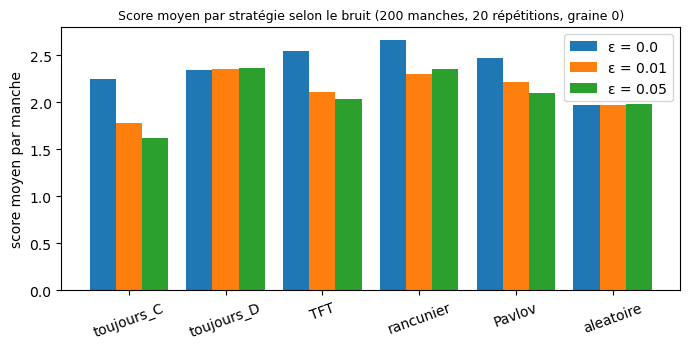

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(noms)); larg = 0.27
for k, eps in enumerate((0.0, 0.01, 0.05)):
    score = dict((n, v) for n, v in resultats[eps][1])
    ax.bar(x + (k - 1) * larg, [score[n] for n in noms], larg, label=f"ε = {eps}")
ax.set_xticks(x); ax.set_xticklabels(noms, rotation=20); ax.set_ylabel("score moyen par manche"); ax.legend()
ax.set_title("Score moyen par stratégie selon le bruit (200 manches, 20 répétitions, graine 0)", fontsize=9)
plt.tight_layout(); plt.show()

Sans bruit, la coopération conditionnelle domine. Avec du bruit, une erreur déclenche des représailles en chaîne chez TFT et le rancunier, et toujours trahir passe en tête dans ce premier essai. **À confirmer** : sur 20 répétitions et une seule graine, l'écart entre les deux premiers à $\varepsilon\geq0{,}01$ est du même ordre que le bruit d'échantillonnage ; le protocole complet (plusieurs graines, intervalles de confiance) est prévu plus tard.

## 6. Dynamique du réplicateur depuis des parts égales

epsilon = 0.0: parts à t = 200 : {'toujours_C': 0.146, 'toujours_D': 0.0, 'TFT': 0.281, 'rancunier': 0.342, 'Pavlov': 0.23, 'aleatoire': 0.0} | somme = 1.0 | min = 0.0
epsilon = 0.01: parts à t = 200 : {'toujours_C': 0.0, 'toujours_D': 0.0, 'TFT': 0.0, 'rancunier': 0.929, 'Pavlov': 0.071, 'aleatoire': 0.0} | somme = 1.0 | min = 0.0
epsilon = 0.05: parts à t = 200 : {'toujours_C': 0.0, 'toujours_D': 0.0, 'TFT': 0.0, 'rancunier': 0.0, 'Pavlov': 1.0, 'aleatoire': 0.0} | somme = 1.0 | min = 0.0


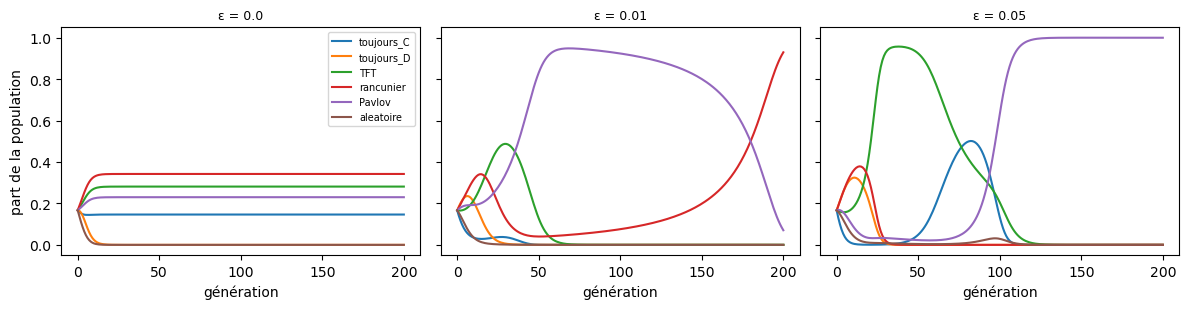

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, eps in zip(axes, (0.0, 0.01, 0.05)):
    traj = replicateur(resultats[eps][0], np.ones(6) / 6, 200)
    for k, n in enumerate(noms):
        ax.plot(traj[:, k], label=n)
    ax.set_title(f"ε = {eps}", fontsize=9); ax.set_xlabel("génération")
    print(f"epsilon = {eps}: parts à t = 200 :", {n: round(float(v), 3) for n, v in zip(noms, traj[-1])},
          "| somme =", round(float(traj[-1].sum()), 12), "| min =", round(float(traj.min()), 6))
axes[0].set_ylabel("part de la population"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Les parts restent positives ou nulles et de somme 1 à chaque génération (propriété testée dans `tests/test_jeux.py`). Sans bruit, les stratégies conditionnelles coopératives se partagent la population et toujours trahir disparaît ; avec du bruit, une seule stratégie tend à l'emporter, et laquelle dépend de la matrice estimée, donc de la graine. **À confirmer** avec plusieurs graines.

## 7. Le TFT généreux

Sept stratégies : on ajoute TFT généreux (pardonne une trahison avec la probabilité 1/3).

In [11]:
for eps in (0.0, 0.05):
    n7, M7, cl7 = tournoi(STRATEGIES_ETENDUES, manches=200, bruit=eps, seed=0, repetitions=20)
    print(f"epsilon = {eps}: " + " > ".join(f"{n} {v:.3f}" for n, v in cl7))

epsilon = 0.0: rancunier 2.707 > TFT 2.601 > Pavlov 2.529 > TFT_genereux 2.524 > toujours_C 2.358 > toujours_D 2.349 > aleatoire 2.089
epsilon = 0.05: toujours_D 2.383 > rancunier 2.373 > Pavlov 2.190 > TFT 2.137 > aleatoire 2.101 > TFT_genereux 2.099 > toujours_C 1.801


## 8. Ce qu'il faut retenir

1. À une manche, $(D,D)$ est l'unique équilibre de Nash et il est Pareto-dominé.
2. À horizon fini connu, l'induction à rebours donne la trahison à chaque manche, même sur 200 manches.
3. À horizon indéterminé, le rancunier soutient la coopération dès $\delta\geq1/2$ et TFT dès $\delta\geq2/3$ ; la simulation à arrêt aléatoire retrouve le seuil $1/2$.
4. Les scores sont des gains moyens par manche, avec une convention d'auto-jeu écrite et un bruit appliqué aux deux joueurs.